# H15. 센서끼리 정보가 겹치는가 (다중공선성)

| 항목 | 내용 |
|---|---|
| 질문 | 온도 센서 4개처럼 거의 같은 값을 내는 센서들이 있을까? |
| 귀무가설 H0 | 센서끼리 상관이 없다 (ρ = 0) |
| 대립가설 H1 | 센서끼리 상관이 있다 |
| 검정 | Spearman 상관 검정, 분산팽창계수(VIF), 차분 후 상관(가짜 상관 점검) |
| 출처 (EDA) | F10 상관 히트맵 |
| 데이터 | 센서 평균 16개 (PS4 제외) |
| 왜 중요한가 | 선형 모델 규제 필요성, 특징 중요도 해석, 특징 축소 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

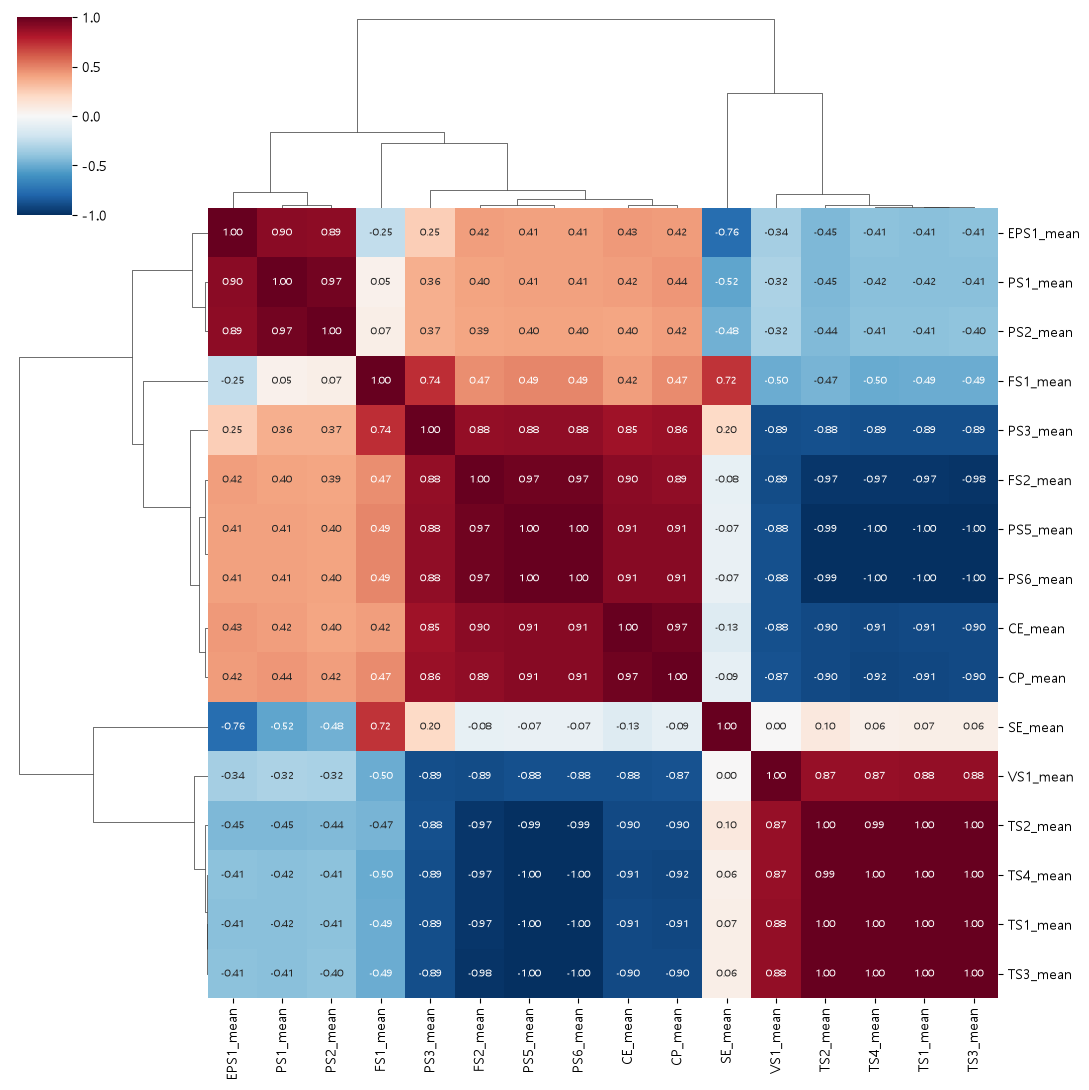

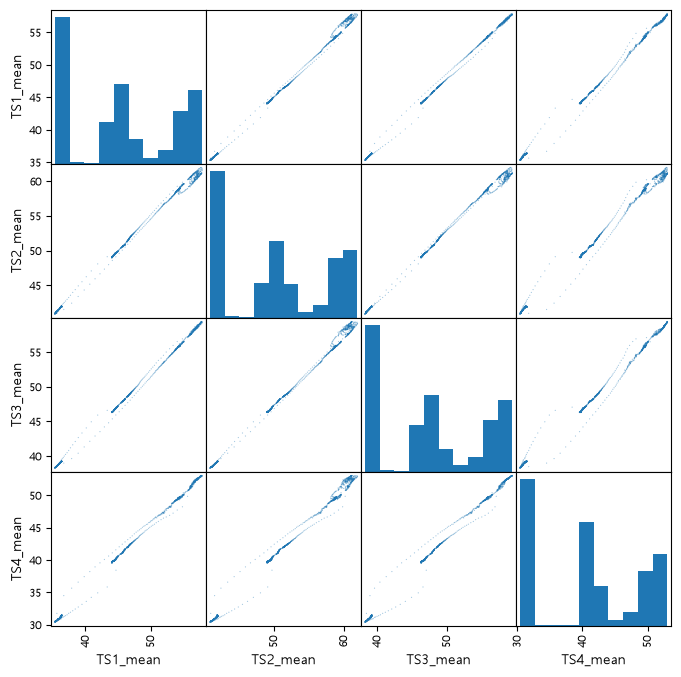

In [2]:
MEAN = [x for x in features(cyc) if x.endswith("_mean") and x != "PS4_mean"]
sns.clustermap(cyc[MEAN].corr(method="spearman"), cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", figsize=(11, 11), annot_kws={"size": 7}); plt.show()
TS = ["TS1_mean", "TS2_mean", "TS3_mean", "TS4_mean"]
pd.plotting.scatter_matrix(cyc[TS], figsize=(8, 8), s=3, alpha=0.4); plt.show()

## 2. 기술통계

In [3]:
display(cyc[TS].describe().round(2))

,TS1_mean,TS2_mean,TS3_mean,TS4_mean
count,2205.00,2205.00,2205.00,2205.00
mean,45.42,50.37,47.66,40.74
std,7.99,7.40,7.45,8.11
min,35.31,40.86,38.25,30.39
25%,36.24,41.86,39.12,31.27
50%,44.84,49.78,47.07,40.43
75%,54.10,58.58,55.69,49.41
max,57.90,61.96,59.42,53.06


## 3. 가정 확인

- Spearman 상관은 정규성 가정이 없습니다.
- **두 시계열이 모두 비정상이면 상관이 실제보다 크게 나오는 "가짜 상관"**이 생길 수 있습니다. 그래서 4단계에서 정상성을 보고, 7단계에서 차분한 값으로 다시 상관을 봅니다.

## 4. 정상성 확인

사이클 순서대로 본 이 특징이 **정상(평균·분산이 시간에 따라 일정)**인지 확인합니다. ADF(H0: 비정상)와 KPSS(H0: 정상)는 질문이 반대라서 함께 봅니다.

- 비정상이거나 자기상관이 크면 "관측값이 서로 독립"이라는 검정의 가정이 약해집니다. 그래서 7단계에서 **50사이클 블록 평균으로 다시 검정**합니다.
- KPSS p가 0.01이나 0.10으로 나오면 경계값입니다. 각각 "0.01 이하", "0.10 이상"으로 읽습니다.


,특징,계열,ADF_p,KPSS_p,판정
0,TS1_mean,원값,0.8718,0.010,비정상
1,TS1_mean,1차 차분,0.0000,0.023,추세·구조변화(둘 다 기각)
2,TS2_mean,원값,0.8823,0.010,비정상
3,TS2_mean,1차 차분,0.0000,0.023,추세·구조변화(둘 다 기각)
4,TS3_mean,원값,0.8782,0.010,비정상
5,TS3_mean,1차 차분,0.0000,0.021,추세·구조변화(둘 다 기각)
6,TS4_mean,원값,0.8987,0.010,비정상
7,TS4_mean,1차 차분,0.0000,0.024,추세·구조변화(둘 다 기각)


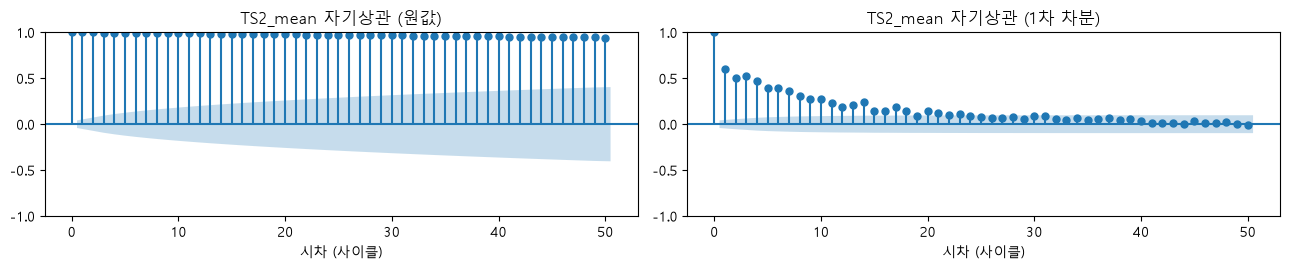

In [4]:
st = stationarity(cyc, ['TS1_mean', 'TS2_mean', 'TS3_mean', 'TS4_mean'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['TS2_mean'], "TS2_mean 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['TS2_mean'].diff(), "TS2_mean 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

## 5. 가설검정 (p-값) — 온도 센서끼리 상관

In [5]:
rows = [dict(쌍=f"{a}–{b}", rho=stats.spearmanr(cyc[a], cyc[b])[0], p=stats.spearmanr(cyc[a], cyc[b])[1]) for a, b in itertools.combinations(TS, 2)]
res = pd.DataFrame(rows); res["p_holm"] = holm(res["p"]); display(res.style.format({"rho": "{:.4f}", "p": "{:.2e}", "p_holm": "{:.2e}"}))

,쌍,rho,p,p_holm
0,TS1_mean–TS2_mean,0.9973,0.00e+00,0.00e+00
1,TS1_mean–TS3_mean,0.9993,0.00e+00,0.00e+00
2,TS1_mean–TS4_mean,0.9983,0.00e+00,0.00e+00
3,TS2_mean–TS3_mean,0.9968,0.00e+00,0.00e+00
4,TS2_mean–TS4_mean,0.9949,0.00e+00,0.00e+00
5,TS3_mean–TS4_mean,0.9975,0.00e+00,0.00e+00


## 6. 효과 크기: VIF

VIF는 "다른 특징들로 이 특징을 얼마나 잘 설명할 수 있나"입니다. **10 이상이면 심한 다중공선성**으로 봅니다.

In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
Z = StandardScaler().fit_transform(cyc[MEAN])
vif = pd.Series({m: variance_inflation_factor(Z, i) for i, m in enumerate(MEAN)}).sort_values(ascending=False)
display(vif.to_frame("VIF").style.format("{:,.0f}"))
print(f"VIF > 10: {(vif > 10).sum()} / {len(vif)}")

,VIF
TS4_mean,"455,704"
TS3_mean,"368,373"
PS5_mean,"130,431"
PS6_mean,"124,921"
TS1_mean,"16,619"
CP_mean,"8,344"
FS1_mean,"6,685"
SE_mean,"5,193"
TS2_mean,"3,866"
PS2_mean,"1,619"


VIF > 10: 16 / 16


## 7. 재확인: 차분 후 상관 (가짜 상관 점검)

시간 추세를 뺀 1차 차분끼리도 상관이 높으면, 센서들이 **실제로 같은 것을 재는** 것입니다.

In [7]:
dres = pd.DataFrame([dict(쌍=f"{a}–{b}", rho_원값=stats.spearmanr(cyc[a], cyc[b])[0], rho_차분=stats.spearmanr(cyc[a].diff().dropna(), cyc[b].diff().dropna())[0])
                     for a, b in itertools.combinations(TS, 2)])
display(dres.round(3))

,쌍,rho_원값,rho_차분
0,TS1_mean–TS2_mean,0.997,0.575
1,TS1_mean–TS3_mean,0.999,0.304
2,TS1_mean–TS4_mean,0.998,0.284
3,TS2_mean–TS3_mean,0.997,0.335
4,TS2_mean–TS4_mean,0.995,0.237
5,TS3_mean–TS4_mean,0.997,0.359


## 8. 최종 판정

In [8]:
final = pd.DataFrame([dict(가설="H15", 검정="Spearman + VIF", 통계량=f"온도 센서 ρ = {res.rho.min():.3f}~{res.rho.max():.3f}", p_holm_최대=res.p_holm.max(),
    효과크기=f"VIF > 10: {(vif > 10).sum()}/{len(vif)}", 차분후_rho=f"{dres.rho_차분.min():.2f}~{dres.rho_차분.max():.2f}",
    판정="H0 기각 (다중공선성 심함)" if res.p_holm.max() < ALPHA and (vif > 10).mean() > 0.5 else "H0 기각" if res.p_holm.max() < ALPHA else "H0 유지")])
display(final)
save_result("H15", title="센서 중복 (다중공선성)", test="Spearman, VIF", stat=final.통계량[0], p=float(res.p_holm.max()), effect=final.효과크기[0], verdict=final.판정[0])

,가설,검정,통계량,p_holm_최대,효과크기,차분후_rho,판정
0,H15,Spearman + VIF,온도 센서 ρ = 0.995~0.999,0.0,VIF > 10: 16/16,0.24~0.57,H0 기각 (다중공선성 심함)


저장: results/H15.json


## 9. 해석과 결정

- 온도 센서 4개는 거의 같은 값을 냅니다. 센서 평균 16개의 VIF도 모두 10을 넘습니다.
- 그런데 1차 차분한 값끼리의 상관은 **0.24~0.57로 크게 떨어집니다**(7단계). 원값 상관 0.99 대부분이 **공통 추세(유온 드리프트) 때문에 생긴 상관**이라는 뜻입니다. 사이클 사이의 짧은 변화는 센서마다 꽤 다르게 움직입니다.
- **결정:**
  1. 선형 모델에는 **규제(Ridge)나 축소(LDA shrinkage)**를 씁니다.
  2. RF의 특징 중요도는 겹치는 센서끼리 나눠 가지므로 **해석할 때 조심**합니다.
  3. 특징을 줄여도 성능이 크게 떨어지지 않을 가능성이 높습니다. 스케일링 비교(4.1.4) 때 함께 확인합니다.